# 05 — Exploratory embryo-transfer outcome classification

Target: `clinical_pregnancy_outcome` (simulated 0/1). Include only cycles with an embryo transfer and known target. Exclude synthetic IDs, cycle date, all outcome columns except target, and the derived blastocyst indicator (redundant with developmental stage). GroupShuffleSplit holds out patients so repeat cycles cannot leak across train/test. Preprocessing is fitted inside model pipelines.

Split evidence: {'known_transfer_outcomes': 2876, 'train_cycles': 2297, 'test_cycles': 579, 'train_patients': 1634, 'test_patients': 409, 'patient_overlap': 0, 'target_positive_rate_train': 0.47453199825859815, 'target_positive_rate_test': 0.47322970639032813, 'target': 'clinical_pregnancy_outcome', 'features': ['cycle_number', 'patient_age', 'infertility_duration_months', 'bmi', 'afc', 'amh_ng_ml', 'stimulation_days', 'estradiol_pg_ml', 'progesterone_ng_ml', 'total_oocytes', 'mature_oocytes', 'fertilization_count', 'embryos_formed', 'day_of_embryo_transfer', 'embryos_transferred', 'endometrial_thickness_mm', 'treatment_cycle_cost_inr', 'infertility_factor', 'stimulation_protocol', 'embryo_grade_category', 'embryo_developmental_stage'], 'excluded': ['synthetic_patient_id', 'synthetic_cycle_id', 'cycle_date', 'clinical_pregnancy_outcome', 'biochemical_pregnancy_outcome', 'live_birth_outcome', 'blastocyst_indicator (redundant with stage)'], 'synthetic_data_warning': 'Metrics evaluate onl

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Dummy majority baseline,0.527,0.000,0.000,0.000,0.500
Logistic regression,0.598,0.570,0.609,0.589,0.641
Random forest,0.603,0.577,0.599,0.588,0.612


,importance
patient_age,0.138526
amh_ng_ml,0.124420
estradiol_pg_ml,0.067434
endometrial_thickness_mm,0.061194
bmi,0.060962
infertility_duration_months,0.059377
treatment_cycle_cost_inr,0.059063
progesterone_ng_ml,0.054103
embryo_grade_category_C,0.047190
embryo_grade_category_A,0.045755


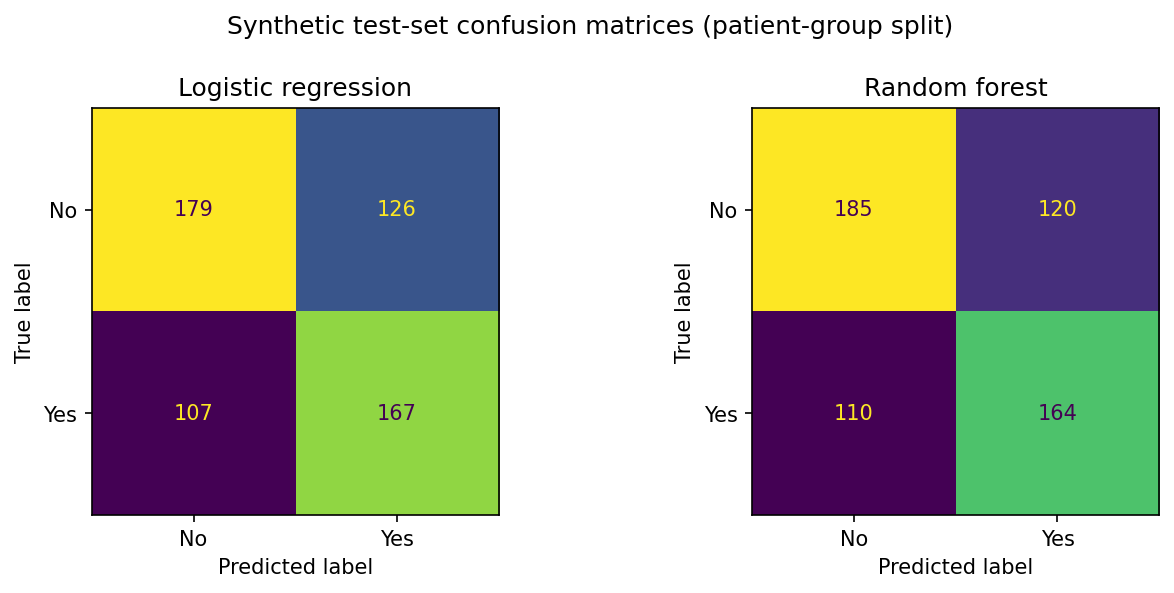

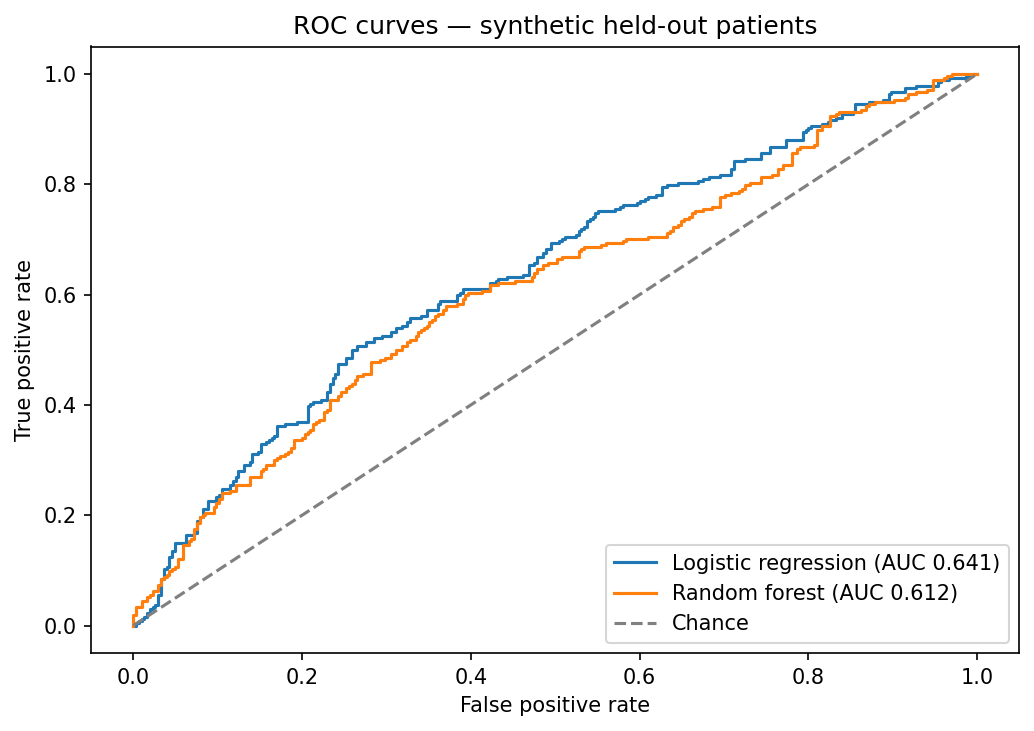

In [1]:
from src.modeling import run_models
from IPython.display import display, Image
scores, split, y_test, predictions, probabilities, importance = run_models()
print("Split evidence:", split)
display(scores.round(3))
display(importance.head(15).to_frame("importance"))
display(Image(filename="visuals/model_confusion_matrices.png"))
display(Image(filename="visuals/model_roc_curves.png"))

## Model interpretation and limits
The Dummy prior baseline provides a reference. Logistic Regression and Random Forest are evaluated using accuracy, precision, recall, F1 and ROC-AUC. Metrics are specific to a random held-out group of synthetic patients and the generator's probability rule; they do not establish real-world clinical accuracy. Do not use for treatment selection, counselling or clinical decisions. Feature importance is not causal and may be biased by correlated predictors.